In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from plot_style import apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "slow_switch_timeseries_data.npz"
OUTPUT = FIG / "Fig14.pdf"

apply()

with np.load(DATA_PATH) as data:
    time = data["t"]
    phi = data["phi"]
    shaded_label = data["shaded_label"]
    shaded_inside = data["shaded_inside"].astype(bool)
    TAU_MIN = float(data["tau_min"])
    ANCHORS_2D = data["anchors_2d"]
    SADDLE_PROJECTION = data["saddle_projection"]

In [2]:
def panel_label(ax, label, dx_pt=-12.0, dy_pt=4.0, fontsize=8.6):
    transform = ax.transAxes + mtransforms.ScaledTranslation(
        dx_pt / 72.0, dy_pt / 72.0, ax.figure.dpi_scale_trans
    )
    ax.text(
        0.0, 1.0, label, transform=transform, ha="left", va="bottom",
        fontsize=fontsize, fontweight="bold", color="#222222",
        clip_on=False, zorder=30,
    )

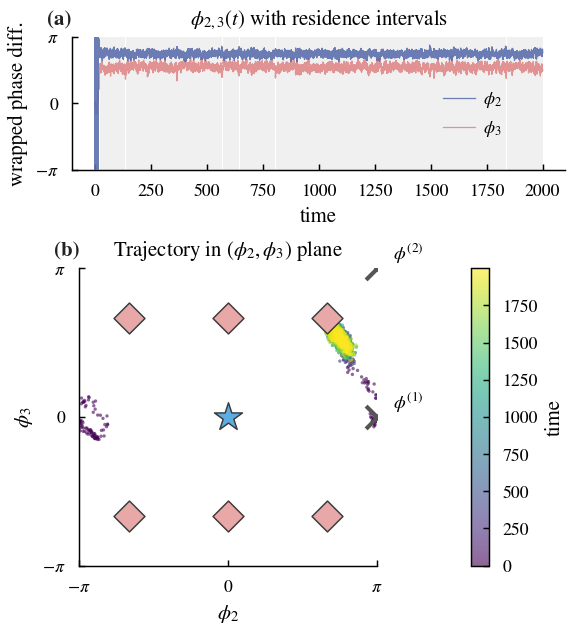

In [3]:
fig = plt.figure(figsize=(3.8, 4.2), constrained_layout=True)
layout = fig.add_gridspec(2, 1, height_ratios=[1, 3])
axis_time = fig.add_subplot(layout[0])
lower_layout = layout[1].subgridspec(1, 2, width_ratios=[1, 0.04], wspace=0.08)
axis_phase = fig.add_subplot(lower_layout[0])
colorbar_axis = fig.add_subplot(lower_layout[1])

number_of_samples = len(time)
index = 0
while index < number_of_samples:
    if not shaded_inside[index]:
        index += 1
        continue
    current_label = shaded_label[index]
    end = index
    while (
        end < number_of_samples
        and shaded_inside[end]
        and shaded_label[end] == current_label
    ):
        end += 1
    if time[end - 1] - time[index] >= TAU_MIN:
        axis_time.axvspan(
            time[index], time[end - 1],
            color="0.82", alpha=0.32, linewidth=0, zorder=1,
        )
    index = end

axis_time.plot(time, phi[:, 1], color="#5B6FAD", linewidth=0.6, alpha=0.9,
               label=r"$\phi_{2}$", zorder=3)
axis_time.plot(time, phi[:, 2], color="#E08888", linewidth=0.6, alpha=0.9,
               label=r"$\phi_{3}$", zorder=2)
axis_time.set_xlabel("time")
axis_time.set_ylabel("wrapped phase diff.")
axis_time.set_ylim(-np.pi, np.pi)
axis_time.set_yticks([-np.pi, 0.0, np.pi])
axis_time.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
axis_time.set_title(r"$\phi_{2,3}(t)$ with residence intervals")
axis_time.tick_params(direction="in", pad=6.5)
panel_label(axis_time, "(a)", fontsize=10)
axis_time.legend(loc="upper right", frameon=False, bbox_to_anchor=(0.9, 0.7))

subsample = slice(0, number_of_samples, 8)
trajectory_plot = axis_phase.scatter(
    phi[subsample, 1], phi[subsample, 2],
    c=time[subsample], cmap="viridis",
    s=2.6, alpha=0.6, edgecolors="none", zorder=2,
)
colorbar = fig.colorbar(trajectory_plot, cax=colorbar_axis, orientation="vertical")
colorbar.set_label("time")

for anchor_index, anchor in enumerate(ANCHORS_2D):
    if anchor_index == 0:
        axis_phase.scatter(
            anchor[0], anchor[1], marker="*", s=200,
            color="#5DADE2", edgecolor="#3a3a3a", linewidth=0.7, zorder=5,
        )
    else:
        axis_phase.scatter(
            anchor[0], anchor[1], marker="D", s=110,
            color="#E8A8A8", edgecolor="#3a3a3a", linewidth=0.7, zorder=5,
        )

for saddle_index, saddle_label in ((0, r"$\phi^{(1)}$"), (2, r"$\phi^{(2)}$")):
    saddle = SADDLE_PROJECTION[saddle_index]
    axis_phase.scatter(
        saddle[0], saddle[1], marker="x", s=120,
        color="#555555", linewidth=2.0, zorder=6,
    )
    axis_phase.annotate(
        saddle_label, saddle, xytext=(8, 4),
        textcoords="offset points", fontsize=9,
    )

axis_phase.set_xlim(-np.pi, np.pi)
axis_phase.set_ylim(-np.pi, np.pi)
axis_phase.set_xticks([-np.pi, 0.0, np.pi])
axis_phase.set_xticklabels([r"$-\pi$", "0", r"$\pi$"])
axis_phase.set_yticks([-np.pi, 0.0, np.pi])
axis_phase.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
axis_phase.set_aspect("equal")
axis_phase.set_xlabel(r"$\phi_{2}$")
axis_phase.set_ylabel(r"$\phi_{3}$")
axis_phase.set_title(r"Trajectory in $(\phi_{2},\phi_{3})$ plane")
axis_phase.tick_params(direction="in", pad=6.5)
colorbar_axis.tick_params(direction="in", pad=6.5)
panel_label(axis_phase, "(b)", fontsize=10)

fig.savefig(OUTPUT)
plt.show()